# Supplementary Figure S7 — QC / batch diagnostics on the integrated UMAP

Mouse cortex, 1,577 QC-passed cells. Panels A–F on the joint (three-modality)
embedding: biological replicate before and after Harmony, library-prep batch,
and four per-cell QC measures.

| § | What it does |
|---|---|
| §1 | setup — paths and libraries |
| §2 | shared helpers |
| §3 | the **uncorrected** (pre-Harmony) joint embedding — the "before correction" half of panel A |
| §4 | draws panels A–F and writes `joint_umap_qc_panels.{pdf,png}` |

§3 and §4 read the embeddings, layouts and annotation from
`subset_clustering/250kb_denovo/{tables,annotation}/`, which
`main_figures/fig3/fig3_umap.ipynb` writes. That is what lets this notebook run
on its own, without the embedding chain that precedes these panels in the Fig-3
notebook (where they appear as §8.7c).


In [1]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has setwd() away.
if (!exists(".repo_root")) {
  .r <- getwd()
  while (.r != "/" && !file.exists(file.path(.r, "paths.R"))) .r <- dirname(.r)
  stopifnot(file.exists(file.path(.r, "paths.R")))
  .repo_root <- .r
}
source(file.path(.repo_root, "paths.R"))

# §1 Setup
Sys.setenv(RETICULATE_PYTHON = file.path(CONDA_ENVS, "scnomehic/bin/python"))
library(reticulate)
use_python(Sys.getenv("RETICULATE_PYTHON"), required = TRUE)

suppressPackageStartupMessages({
  library(umap); library(impute); library(igraph); library(cccd); library(Matrix)
  library(rhdf5); library(RColorBrewer); library(harmony)
  library(dplyr); library(tidyr); library(tibble); library(ggplot2); library(patchwork)
})
set.seed(42)

WORKDIR <- file.path(WORK, "mouse_cortex")
OUT_DIR <- file.path(WORKDIR, "subset_clustering", "250kb_denovo")
OUT_TAB <- file.path(OUT_DIR, "tables")
OUT_FIG <- file.path(OUT_DIR, "figures")
ANN_DIR <- file.path(OUT_DIR, "annotation")
for (d in c(OUT_TAB, OUT_FIG, ANN_DIR)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(WORKDIR); par(bg = "white")

In [2]:
# §2 Helpers
filter_high_na_genes <- function(mat, thr = 0.5) {
  mat[rowMeans(is.na(mat)) < thr, , drop = FALSE]
}

quantile_normalize <- function(mat) {
  nr <- nrow(mat); nc <- ncol(mat)
  max_non_na <- max(colSums(!is.na(mat)))
  sorted <- matrix(NA_real_, nrow = max_non_na, ncol = nc)
  for (i in seq_len(nc)) {
    v <- mat[, i]; v <- sort(v[!is.na(v)])
    sorted[seq_along(v), i] <- v
  }
  rmean <- rowMeans(sorted, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = nr, ncol = nc, dimnames = dimnames(mat))
  for (i in seq_len(nc)) {
    v <- mat[, i]; na_idx <- is.na(v)
    out[!na_idx, i] <- rmean[rank(v[!na_idx], ties.method = "average")]
  }
  out
}

impute_relaxed <- function(mat, k = 10) {
  suppressWarnings(suppressMessages(
    impute::impute.knn(mat, k = k, maxp = "p", rowmax = 0.95, colmax = 0.95)$data))
}

# Matches `perform_imputation` in the exploration notebook — uses impute.knn's
# stricter defaults (rowmax=0.5, colmax=0.8) so the SVD/Harmony/UMAP
# downstream agree with the exploration sweep figures.
perform_imputation <- function(data_mat, k = 10) {
  suppressWarnings(suppressMessages(
    impute::impute.knn(data_mat, k = k, maxp = "p")$data))
}

svd_embedding <- function(mat_features_x_cells, n_comps = 20) {
  data_t <- t(mat_features_x_cells)
  sv <- svd(scale(data_t))
  out <- sv$u[, seq_len(min(n_comps, ncol(sv$u))), drop = FALSE]
  rownames(out) <- rownames(data_t)
  attr(out, "svd") <- sv
  out
}

build_knn_graph <- function(emb, n_pc, k) {
  ng  <- min(n_pc, ncol(emb))
  knn <- cccd::nng(emb[, seq_len(ng), drop = FALSE], k = k)
  if ("weight" %in% igraph::edge_attr_names(knn))
    knn <- igraph::delete_edge_attr(knn, "weight")
  igraph::as.undirected(knn, mode = "collapse")
}

run_leiden <- function(emb, n_pc = 3, k = 25, resolution = 0.2) {
  g   <- build_knn_graph(emb, n_pc, k)
  com <- igraph::cluster_leiden(g, objective_function = "modularity",
                                resolution_parameter = resolution, n_iterations = 5)
  as.integer(igraph::membership(com))
}

partition_colors <- function(p, palette = brewer.pal(8, "Dark2")) {
  col <- rep(palette[1], length(p))
  for (i in unique(p)) col[p == i] <- palette[((i - 1) %% length(palette)) + 1]
  col
}

make_umap_df <- function(layout, meta) {
  as.data.frame(layout) %>% setNames(c("UMAP1", "UMAP2")) %>%
    tibble::rownames_to_column("cell") %>% dplyr::left_join(meta, by = "cell")
}

# --- figure savers: write BOTH pdf + png (and render inline) ---
# base graphics: `draw` is a no-arg function that renders the plot
save_fig_both <- function(basepath, width, height, draw) {
  pdf(paste0(basepath, ".pdf"), width = width, height = height); draw(); dev.off()
  png(paste0(basepath, ".png"), width = width, height = height, units = "in", res = 150); draw(); dev.off()
  invisible(NULL)
}
# ggplot objects
ggsave_both <- function(basepath, plot, width, height) {
  ggplot2::ggsave(paste0(basepath, ".pdf"), plot, width = width, height = height)
  ggplot2::ggsave(paste0(basepath, ".png"), plot, width = width, height = height, dpi = 150)
  invisible(NULL)
}


## §3 Uncorrected (pre-Harmony) joint embedding

The same recipe as the corrected joint embedding, but on the **raw** per-modality
SVDs with no Harmony step — this is the "before correction" half of panel A.

Deterministic: two independent recomputes agree to `0.000e+00`.


In [28]:
# §3 Uncorrected (pre-Harmony) joint embedding = the "before batch correction"
# half of panel A. Same recipe as the corrected joint embedding, but on the RAW
# per-modality SVD embeddings
# (HCG top-9, Hi-C top-10, GCH top-20), with NO Harmony.
# Resume-friendly: use the in-session SVD objects when this runs inside the Fig-3
# notebook, otherwise read the saved tables (fig3_umap.ipynb §4a/§5a/§6b wrote
# them). Standalone, the second path is always the one taken.
rd_tab <- function(f) as.matrix(read.table(file.path(OUT_TAB, f), header = TRUE,
                                           row.names = 1, check.names = FALSE))
hcg_raw <- if (exists("HCG.svd")) HCG.svd[, seq_len(9),  drop = FALSE] else rd_tab("hcg_svd_raw.txt")
hic_raw <- if (exists("hic_mat")) hic_mat[, seq_len(10), drop = FALSE] else rd_tab("hic_svd_raw.txt")
gch_raw <- if (exists("gch_svd")) gch_svd[, seq_len(20), drop = FALSE] else rd_tab("gch_svd_raw.txt")

shared_u <- Reduce(intersect, list(rownames(hcg_raw), rownames(hic_raw), rownames(gch_raw)))
cat("Uncorrected joint cells:", length(shared_u), "\n")

jc <- cbind(scale(hcg_raw[shared_u, , drop = FALSE]),
            scale(hic_raw[shared_u, , drop = FALSE]),
            scale(gch_raw[shared_u, , drop = FALSE]))
jp <- prcomp(jc, center = FALSE, scale. = FALSE)$x            # decorrelating rotation

ucfg <- umap::umap.defaults
ucfg$n_neighbors  <- 10
ucfg$min_dist     <- 0.2
ucfg$metric       <- "euclidean"
ucfg$random_state <- 42
set.seed(42)
joint_umap_uncorr <- umap::umap(jp, config = ucfg)
rownames(joint_umap_uncorr$layout) <- shared_u
write.table(joint_umap_uncorr$layout, file.path(OUT_TAB, "joint_umap_uncorrected.txt"),
            sep = "\t", quote = FALSE)
cat("uncorrected joint UMAP:", dim(joint_umap_uncorr$layout), "\n")

Uncorrected joint cells: 1577 


uncorrected joint UMAP: 1577 2 


library_prep_date coverage: 1577 / 1577 


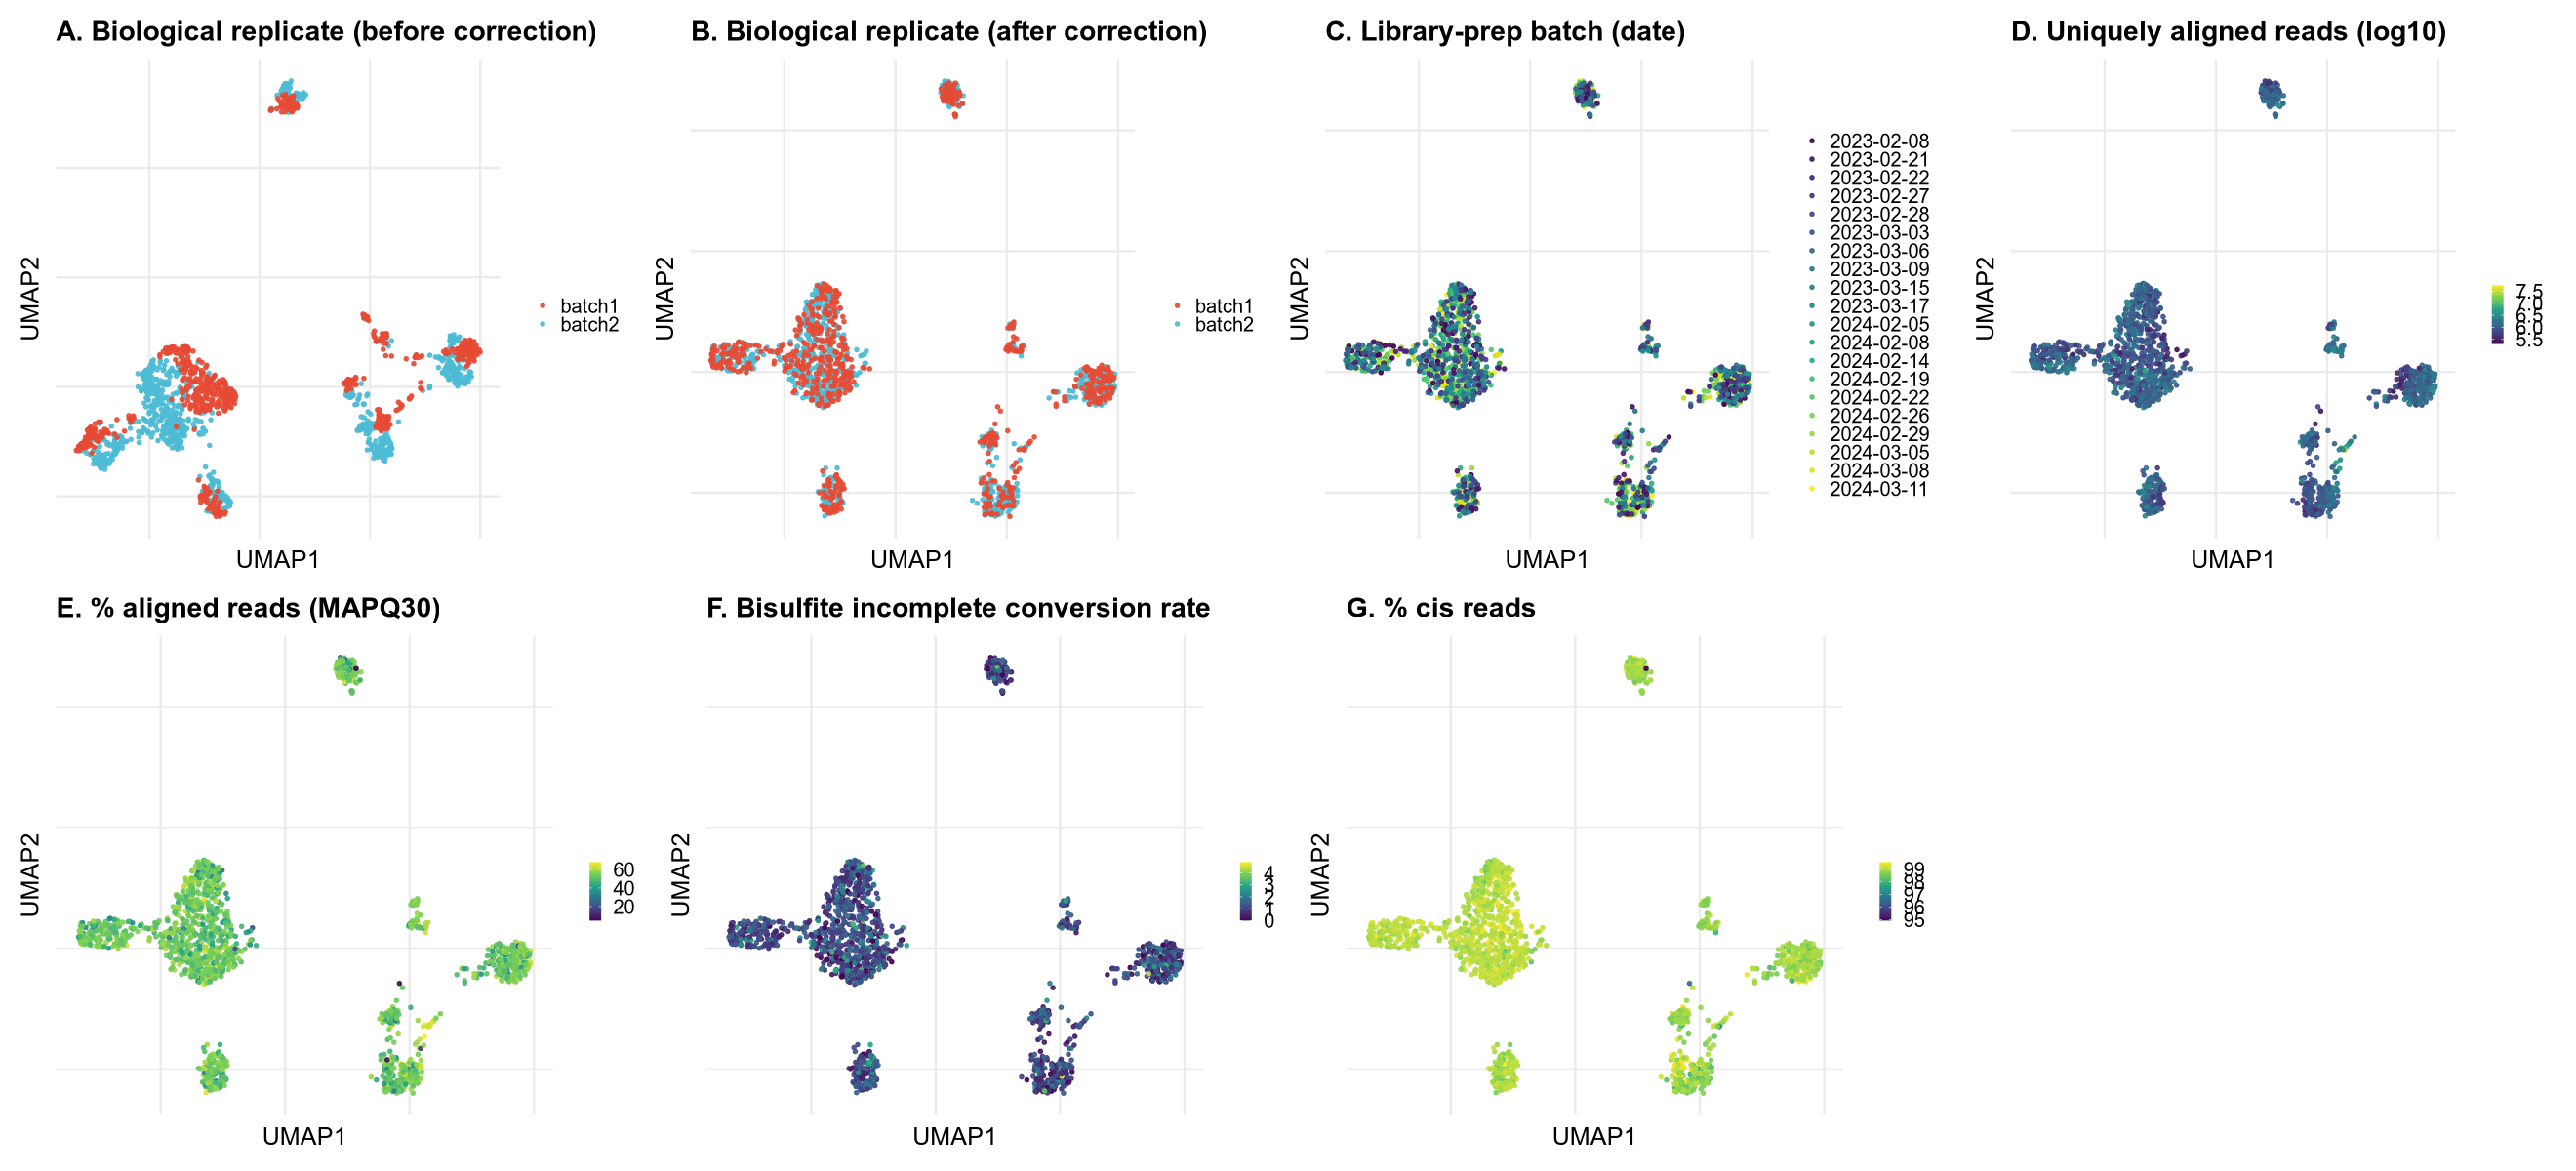

In [3]:
options(repr.plot.width = 22, repr.plot.height = 10)
# §4 QC / batch panels on the integrated UMAP.
# Resume-friendly: load saved metadata / layouts if the in-session objects are absent.
if (!exists("submetadata"))
  submetadata <- read.table(file.path(OUT_TAB, "..", "annotation", "metadata_with_cell_type.txt"),
                            header = TRUE, sep = "\t", row.names = 1, check.names = FALSE,
                            quote = "", comment.char = "")
if (!exists("joint_umap"))
  joint_umap <- list(layout = as.matrix(read.table(file.path(OUT_TAB, "joint_umap.txt"),
                     header = TRUE, row.names = 1, check.names = FALSE)))
if (!exists("joint_umap_uncorr"))
  joint_umap_uncorr <- list(layout = as.matrix(read.table(file.path(OUT_TAB, "joint_umap_uncorrected.txt"),
                     header = TRUE, row.names = 1, check.names = FALSE)))

# plate_ID / library_prep_date are columns of the saved metadata, merged there
# from the two library sample sheets — nothing is read ad-hoc here.
stopifnot("library_prep_date" %in% colnames(submetadata))
cat("library_prep_date coverage:",
    sum(!is.na(submetadata[rownames(joint_umap$layout), "library_prep_date"])),
    "/", nrow(joint_umap$layout), "\n")

num <- function(x) as.numeric(as.character(x))
build_qc_df <- function(layout) {
  cells <- rownames(layout)
  d <- data.frame(UMAP1 = layout[, 1], UMAP2 = layout[, 2], row.names = cells)
  s <- submetadata[cells, "sample"]
  d$replicate <- ifelse(s == "scNH", "batch1", ifelse(s == "batch2", "batch2", s))
  d$Library_prep_date <- factor(submetadata[cells, "library_prep_date"])  # B
  d$log10_uniq   <- log10(num(submetadata[cells, "mapq30num"]))  # D
  d$pct_aligned  <- num(submetadata[cells, "mapq30rate"])        # E
  d$incompl_conv <- num(submetadata[cells, "noncpg_chrM"])       # F (chrM non-CpG = incomplete conversion)
  cisn <- num(submetadata[cells, "cisnum"]); trn <- num(submetadata[cells, "transnum"])
  d$pct_cis <- 100 * cisn / (cisn + trn)                         # G
  d
}
df_after  <- build_qc_df(joint_umap$layout)
df_before <- build_qc_df(joint_umap_uncorr$layout)

qc_theme <- theme_minimal(base_size = 15) +      # publication-size text
  theme(legend.position = "right", axis.text = element_blank(),
        panel.grid.minor = element_blank(),
        plot.title   = element_text(size = 17, face = "bold"),
        axis.title   = element_text(size = 15),
        legend.text  = element_text(size = 12),
        legend.title = element_text(size = 13),
        legend.key.size = unit(0.5, "lines"))
qc_cont <- function(d, col, title)
  ggplot(d, aes(UMAP1, UMAP2, colour = .data[[col]])) +
    geom_point(size = 0.9, alpha = 0.9) +
    scale_color_viridis_c(name = "", na.value = "grey85") + ggtitle(title) + qc_theme
qc_catp <- function(d, col, title, pal = NULL) {
  g <- ggplot(d, aes(UMAP1, UMAP2, colour = .data[[col]])) +
    geom_point(size = 0.9, alpha = 0.9) + ggtitle(title) + qc_theme
  if (!is.null(pal)) g + scale_color_manual(values = pal, na.value = "grey85", name = "")
  else            g + scale_color_viridis_d(na.value = "grey85", name = "")
}
rep_pal <- c(batch1 = "#E64B35", batch2 = "#4DBBD5")

pA0 <- qc_catp(df_before, "replicate", "A. Biological replicate (before correction)", rep_pal)
pA1 <- qc_catp(df_after,  "replicate", "B. Biological replicate (after correction)",  rep_pal)
pB  <- qc_catp(df_after[!is.na(df_after$Library_prep_date), ], "Library_prep_date", "C. Library-prep batch (date)")  # drop NA-date cells
pC  <- qc_cont(df_after,  "log10_uniq",   "D. Uniquely aligned reads (log10)")
pD  <- qc_cont(df_after,  "pct_aligned",  "E. % aligned reads (MAPQ30)")
pE  <- qc_cont(df_after,  "incompl_conv", "F. Bisulfite incomplete conversion rate")
pF  <- qc_cont(df_after,  "pct_cis",      "G. % cis reads")

qc_panel <- (pA0 | pA1 | pB | pC) / (pD | pE | pF | patchwork::plot_spacer())
ggsave_both(file.path(OUT_FIG, "joint_umap_qc_panels"), qc_panel, 22, 10)
qc_panel